# Strip waveguide S-bend 
This notebook contains code that simulates bend waveguide parameters using **Tidy3d**. \
The objective is to obtain loss values across radius sweep.

https://www.flexcompute.com/tidy3d/examples/notebooks/SbendCMAES

In [40]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

# Import modules
from datetime import datetime
import gdsfactory as gf
from gdsfactory.gpdk import PDK
import cma
from IPython.display import display
import lumapi as lma
import math
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [17]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [18]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [19]:
# Si/SiO2 430x220nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

sbend_length = 4*um
sbend_width = 4*um

core_thickness = 220*nm
core_width = 430*nm
bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si (Silicon) - Palik"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [20]:
# Si3N4/SiO2 1000x360nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

sbend_length = 20*um
sbend_width = 5*um

core_thickness = 360*nm
core_width = 1000*nm
bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [21]:
# Pre-calculate parameters for solver
experiment_name = (
    f"{base_core_material.split()[0].lower()}_"
    f"w{int(core_width / nm)}nm_"
    f"h{int(core_thickness / nm)}nm_"
    f"sbendGA_"
    f"w{int(sbend_width / um)}um_"
    f"l{int(sbend_length / um)}um"
)

field_intensity_log_decay = -6

ports_offset = sbend_length/20
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

initial_fdtd_height = initial_ports_height + 2*wavelength_center
initial_fdtd_length = sbend_length + 2*ports_offset + 2*wavelength_center
initial_fdtd_width = sbend_width + initial_ports_width + 2*wavelength_center

frequency_center = C / wavelength_center

In [22]:
# Get solver
solver = lma.FDTD(hide=False)

In [23]:
# Helper for safe removal

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

# Materials

In [24]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

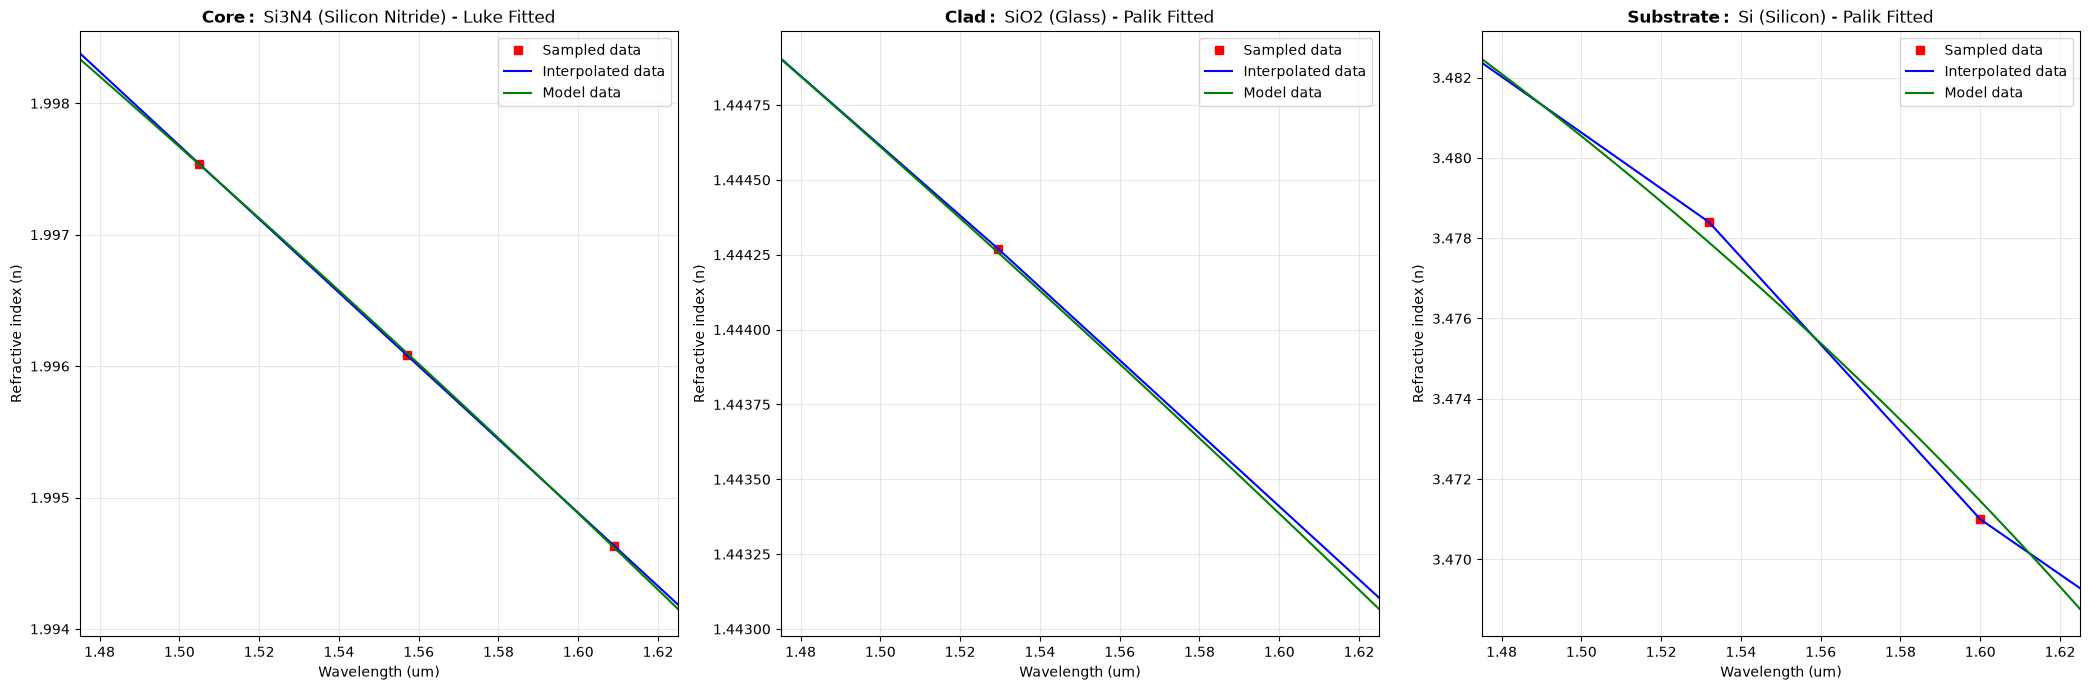

In [25]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

In [26]:
# Structure geometry

clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness

def bezier_curve(control_points, num_points=99):
    t = np.linspace(0, 1, num_points)
    curve = np.zeros((num_points, 2))
    n = len(control_points) - 1  # degree of the Bézier curve

    for i in range(n + 1):
        binomial_coeff = math.factorial(n) / (math.factorial(i) * math.factorial(n - i))
        term = binomial_coeff * (1 - t) ** (n - i) * t**i
        curve += np.outer(term, control_points[i])

    return curve

def make_sbend(v):
    p_input = np.array([-sbend_length/2, -sbend_width/2 - core_width/2])
    p_output = np.array([sbend_length/2, sbend_width/2 - core_width/2])

    sbend_bot_points = np.array(
        [
            p_input,
            [v[0], v[1]],
            [v[2], v[3]],
            [v[4], 0],
            [v[5], v[6]],
            [v[7], v[8]],
            p_output,
        ]
    )

    sbend_bot_curve = bezier_curve(sbend_bot_points)
    sbend_top_curve = -sbend_bot_curve
    vertices = np.vstack((sbend_bot_curve, sbend_top_curve))

    solver.addpoly(
        name="s-bend",
        vertices=vertices,
        z_min=-core_thickness/2,
        z_max=core_thickness/2,
        material=core_material,
    )

# Substrate
remove("substrate")
solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=100*um,
    material=substrate_material,
    alpha=0.8,
)

# Clad
remove("clad")
solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=100*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

# S-bend
p1 = np.array([-sbend_length/4 - core_width/4, -sbend_width/2 - core_width/2])
p2 = np.array([core_width/2, -sbend_width/4 - core_width/4])
p3 = np.array([core_width/2, 0])
p4 = np.array([core_width/2, sbend_width/4 - core_width/4])
p5 = np.array([sbend_length/4 - core_width/4, sbend_width/2 - core_width/2])

sbend_initial_v = np.array([
    p1[0], p1[1],
    p2[0], p2[1],
    p3[0],
    p4[0], p4[1],
    p5[0], p5[1]
])

remove("s-bend")
make_sbend(sbend_initial_v)

# Input waveguide
remove("waveguide-in")
solver.addrect(
    name="waveguide-in",
    x_min=-100*um, x_max=-sbend_length/2,
    y=-sbend_width/2, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

# Output waveguide
remove("waveguide-out")
solver.addrect(
    name="waveguide-out",
    x_min=sbend_length/2, x_max=100*um,
    y=sbend_width/2, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

In [27]:
# Simulation setup

solver.save(f"results/{experiment_name}.fsp")

solver.switchtolayout()

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
    z_span=initial_fdtd_height,
)

solver.setdevice("GPU")
solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Input port
remove("port-in")
solver.addport(
    name="port-in",
    injection_axis="x-axis",
    x=-sbend_length/2 - ports_offset, 
    y=-sbend_width/2, 
    z=0,
    y_span=initial_ports_width, 
    z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Output port
remove("port-out")
solver.addport(
    name="port-out",
    injection_axis="x-axis",
    x=sbend_length/2 + ports_offset, 
    y=sbend_width/2, 
    z=0,
    y_span=initial_ports_width, 
    z_span=initial_ports_height,
    direction="Backward",
);

# Field monitor
remove("field-monitor")
solver.adddftmonitor(
    name="field-monitor",
    monitor_type="2D Z-normal",
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
)

solver.setnamed("FDTD::ports", "override global monitor settings", False)

# Inde monitor
remove("index-monitor")
solver.addindex(
    name="index-monitor",
    monitor_type="2D Z-normal",
    x=0, y=0, z=0,
    x_span=initial_fdtd_length, 
    y_span=initial_fdtd_width, 
)

solver.setglobalmonitor("frequency points", 30)

# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 3)

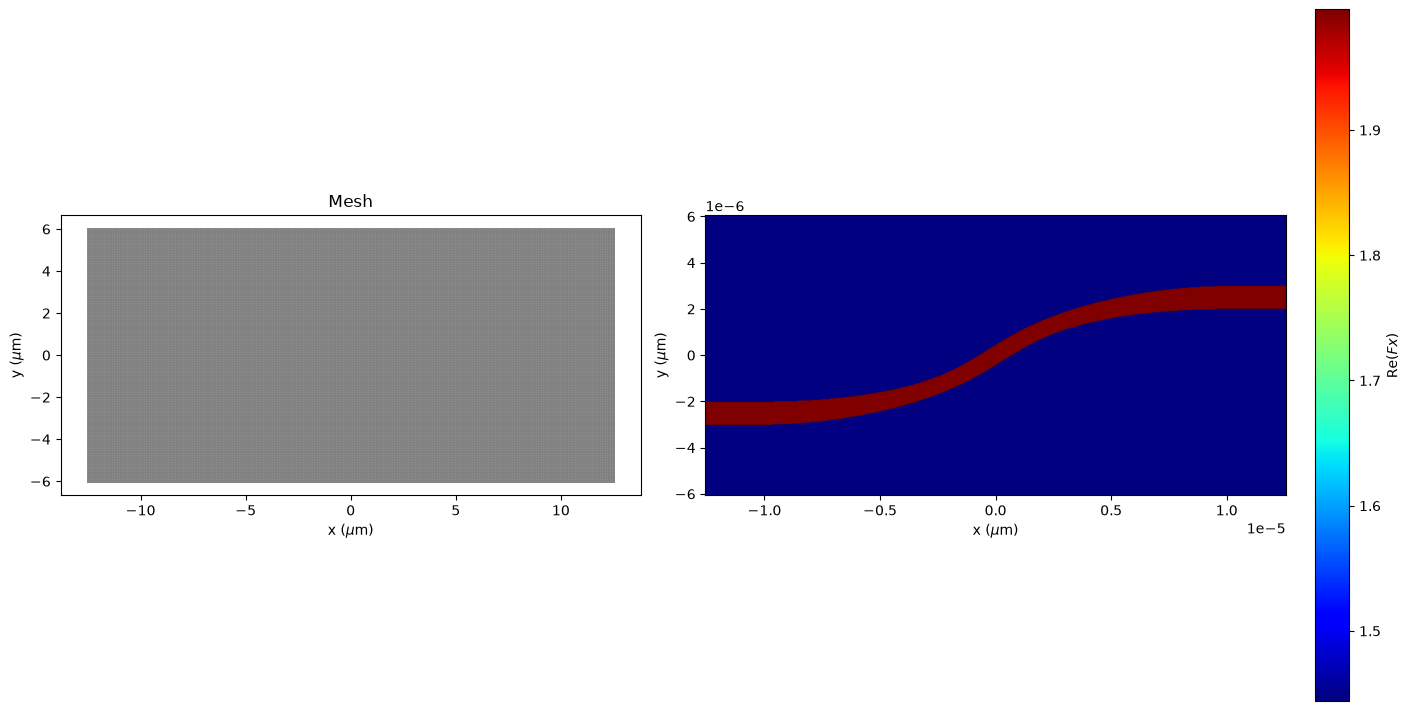

In [28]:
# Simulation preview

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Y = np.meshgrid(x, y, indexing='ij')
ax1.plot(X * 1e6, Y * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Y.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'y ($\mu$m)')
ax1.set_aspect('equal')

# Refractive index
px.plot_field(
    Fx=index_x,
    x=x, y=y,
    ax=ax2,
    scale="lin",
)

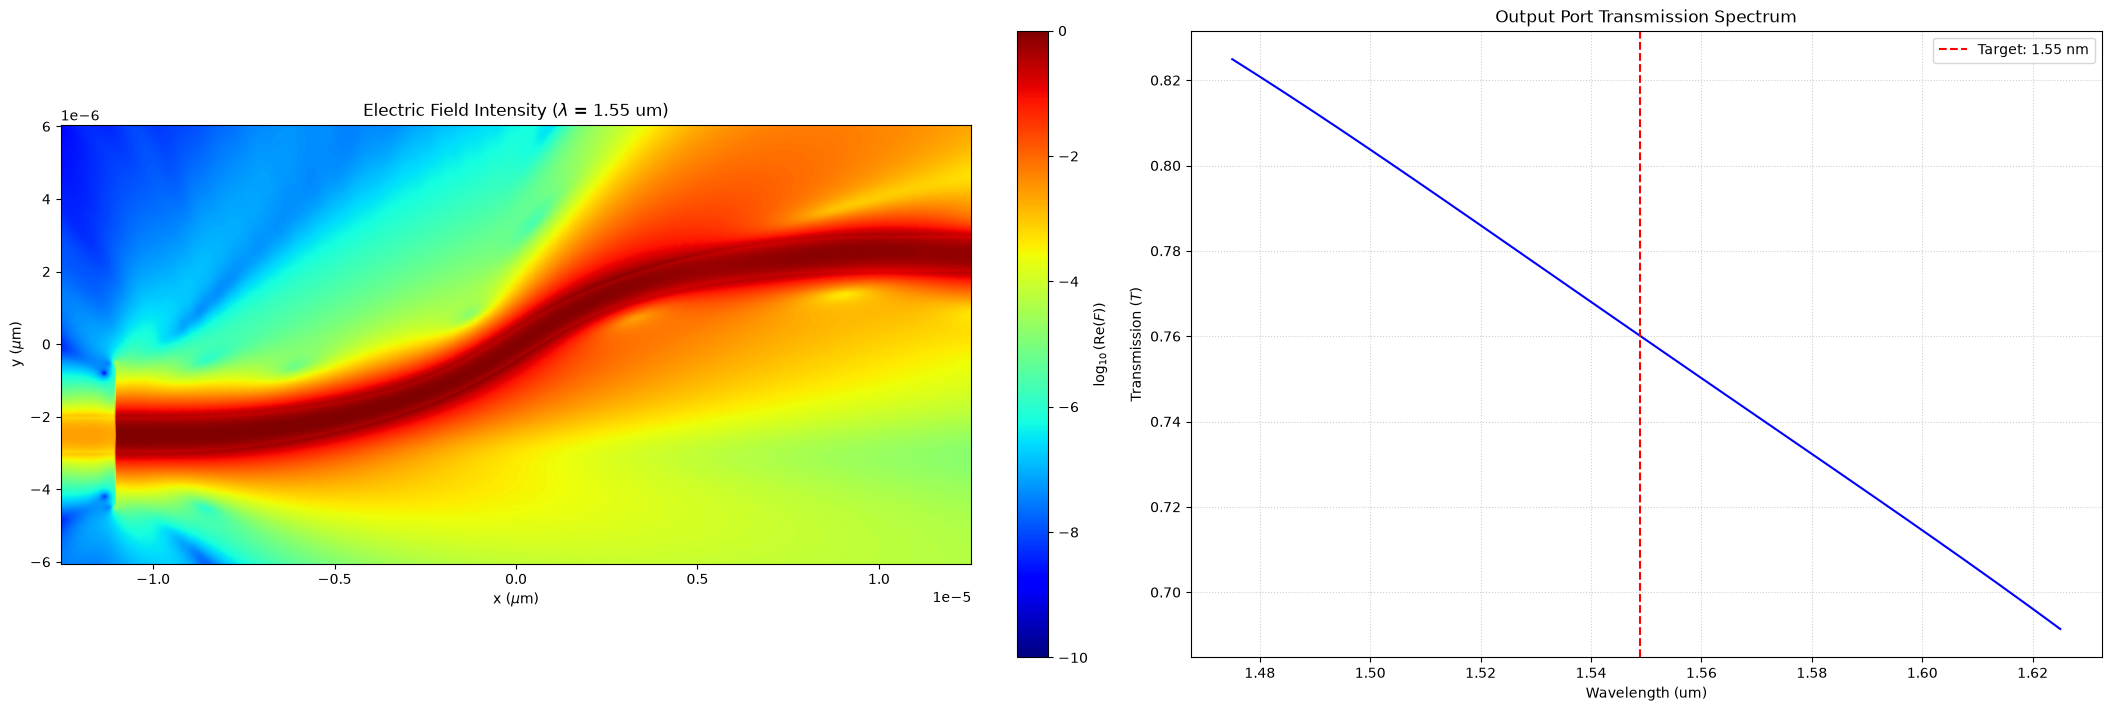

In [29]:
# Initial simulation

# switchtolayout clears solver state so it can be re-run
solver.switchtolayout()
solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

T = solver.getresult("FDTD::ports::port-out", "T")

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T = solver.getresult("FDTD::ports::port-out", "T")
wavelengths = np.squeeze(T["lambda"])
transmission = np.squeeze(T["T"])

ax2.plot(wavelengths*1e6, transmission, color='b')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

# Optimization

In [30]:
def update_sbend(v):
    solver.switchtolayout()
    remove("s-bend")
    make_sbend(v)

def get_mean_transmission_db():
    T = solver.getresult("FDTD::ports::port-out", "T")
    T = np.squeeze(T["T"])
    T_mean = np.mean(T)
    T_db = -10 * np.log10(T_mean + 1e-50)
    print(f"T_db: {T_db}")

    return T_db

def objective_function(vs):
    T = []
    for i, v in enumerate(vs):
        update_sbend(v)
        solver.run()
        T.append(get_mean_transmission_db())

    return T

In [32]:
dim = len(sbend_initial_v)
population_size = 10
max_generations = 15
sigma0 = 100*nm
random_seed = 12345

es = cma.CMAEvolutionStrategy(
    sbend_initial_v, sigma0, {"popsize": population_size, "maxiter": max_generations, "seed": random_seed}
)

(5_w,10)-aCMA-ES (mu_w=3.2,w_1=45%) in dimension 9 (seed=12345, Wed Nov 18 12:52:19 2026)


In [34]:
optimization_data = {
    "generations": [],
    "optimizer": None,
}

solver.switchtolayout()
solver.setnamed("field-monitor", "enabled", False)
solver.setnamed("index-monitor", "enabled", False)

gen_idx = 0
while not es.stop():
    solutions = es.ask()
    function_values = objective_function(solutions)
    es.tell(solutions, function_values)

    f_best = es.result.fbest
    x_best = es.result.xbest
    
    # Store history for this generation
    optimization_data["generations"].append({
        "gen": gen_idx,
        "f_best": f_best,
        "x_best": x_best,
    })

    print(f"Generation {gen_idx}: Best function value = {f_best:.3f}")

    gen_idx += 1

# Save the full optimizer state at the end
optimization_data["optimizer"] = es

T_db: 1.2848920602396081
T_db: 1.1127170986503174
T_db: 1.360910380254653
T_db: 1.2747796144922205
T_db: 1.2712610146986498
T_db: 0.9875983207009492
T_db: 1.1496142415735322
T_db: 1.2247533319390564
T_db: 1.2960258945432181
T_db: 1.0811446719966384
Generation 0: Best function value = 0.988
T_db: 1.0005812401253247
T_db: 1.1885739703515277
T_db: 0.9326927052605369
T_db: 0.8545739169799705
T_db: 0.863448375886499
T_db: 1.0441601787644035
T_db: 0.7202460757268083
T_db: 1.071532484177196
T_db: 1.2797096846289375
T_db: 0.8073372526736246
Generation 1: Best function value = 0.720
T_db: 0.7338708752540085
T_db: 0.9947966335096743
T_db: 0.995828708126124
T_db: 0.7672121724088993
T_db: 0.7224317872511099
T_db: 0.9762787655785456
T_db: 0.6260849966023003
T_db: 0.7713786923902972
T_db: 1.163459520333052
T_db: 0.8037836225666994
Generation 2: Best function value = 0.626
T_db: 0.5953669222092749
T_db: 0.8138203718381156
T_db: 0.5907848579741898
T_db: 0.6785334180362153
T_db: 0.6096449609505882
T_db

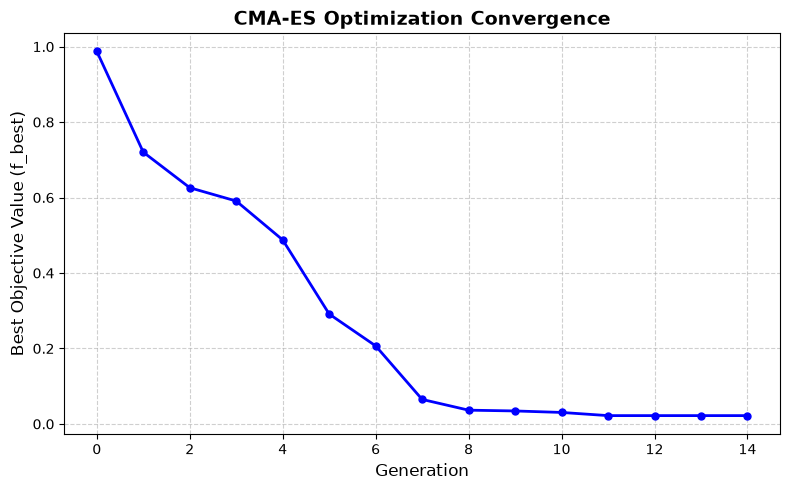

In [38]:
# 1. Extract generations and f_best values from your dictionary
generations = [gen["gen"] for gen in optimization_data["generations"]]
best_fitness_values = [gen["f_best"] for gen in optimization_data["generations"]]

# 2. Create the plot
plt.figure(figsize=(8, 5))
plt.plot(generations, best_fitness_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=5)

# 3. Add labels, grid, and title
plt.title("CMA-ES Optimization Convergence", fontsize=14, fontweight='bold')
plt.xlabel("Generation", fontsize=12)
plt.ylabel("Best Objective Value (f_best)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 4. Show the plot
plt.tight_layout()
plt.show()

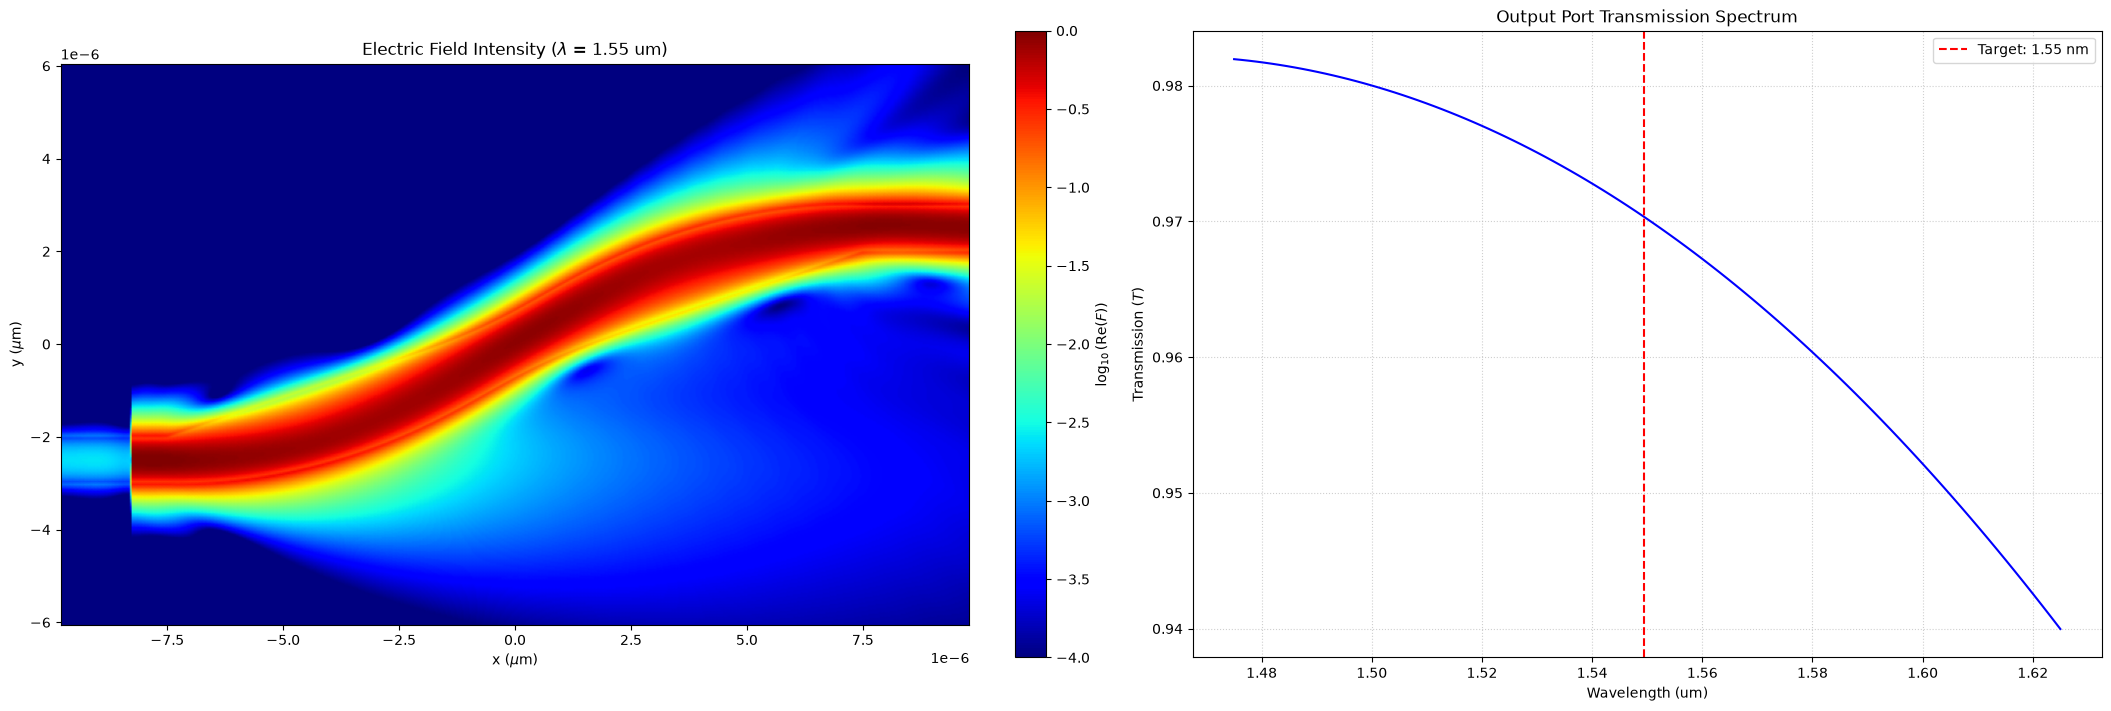

In [219]:
# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

T = solver.getresult("FDTD::ports::port-out", "T")

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-4, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T = solver.getresult("FDTD::ports::port-out", "T")
wavelengths = np.squeeze(T["lambda"])
transmission = np.squeeze(T["T"])

ax2.plot(wavelengths*1e6, transmission, color='b')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

In [220]:
v_opt = es.result[0]
print(v_opt)

[-3.58561048e-06 -2.86368000e-06 -1.67953872e-08 -1.58644144e-06
 -4.61519875e-07  5.55509368e-07 -5.71245920e-07  3.82272255e-06
  3.50597096e-07]


In [41]:
# Export GDS
PDK.activate()
gf.clear_cache()
 
c = gf.Component("s-bend")
 
# Geometry
vertices = solver.getnamed("s-bend", "vertices") * 1e6
c.add_polygon(vertices, layer=(1, 0))
 
# Ports
port_in = ((-sbend_length/2) * 1e6, (-sbend_width/2) * 1e6)
c.add_port(
    name="opt_in",
    center=port_in,
    width=core_width * 1e6,
    orientation=180,
    layer=(1, 0)
)
port_out = ((sbend_length/2) * 1e6, (sbend_width/2) * 1e6)
c.add_port(
    name="opt_out",
    center=port_out,
    width=core_width * 1e6,
    orientation=0,
    layer=(1, 0)
)
 
# 5. Export GDS (fully readable with ports by GDSFactory later)
gds_filename = f"results/{experiment_name}.gds"
c.write_gds(gds_filename)
print(f"Exported GDS file to: {gds_filename}")

Exported GDS file to: results/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds


In [35]:
# Export results
experiment_date = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"results/{experiment_name}_{experiment_date}.npz"
np.savez(filename, optimization_data=optimization_data)
print(f"Data saved under {filename}")

Data saved under results/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um_20261118_172518.npz
